<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df=pd.read_csv('/content/drive/MyDrive/TeachingRatings.csv')
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Mean: 3.9982721382289412
Std Dev: 0.5548655656195949


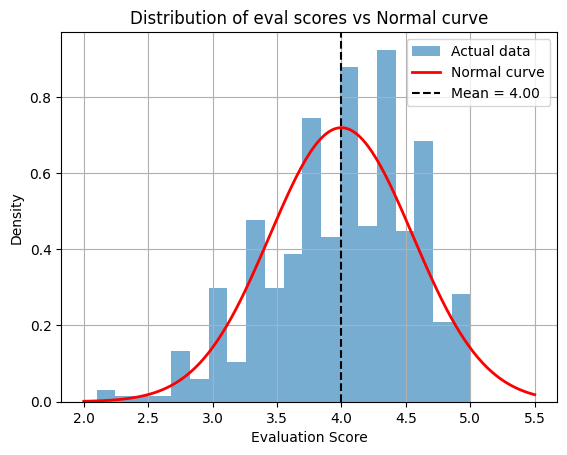


1. The mean evaluation is 3.998 and the standard deviation is 0.555. These two numbers fully define the normal model used in Q1 and Q2.
2. Skewness = -0.47. A negative value means a longer tail on the low side: most ratings are high, with a few very low ones.
3. The data is not a perfect bell curve (gaps between bars, and a hard ceiling at 5), so the normal model is only an approximation.
4. The fitted normal curve gives 3.6% probability to scores above 5, which is impossible. This shows the limit of the approximation.



In [6]:
mean_score = df['eval'].mean()
std_score = df['eval'].std()
skew_score = df['eval'].skew()
p_above_5 = stats.norm.sf(5, loc=mean_score, scale=std_score)

print("Mean:", mean_score)
print("Std Dev:", std_score)

df['eval'].hist(bins=20, density=True, alpha=0.6, label='Actual data')
xs = np.linspace(2, 5.5, 200)
plt.plot(xs, stats.norm.pdf(xs, mean_score, std_score), color='red', linewidth=2, label='Normal curve')
plt.axvline(mean_score, color='black', linestyle='--', label=f'Mean = {mean_score:.2f}')
plt.xlabel("Evaluation Score")
plt.ylabel("Density")
plt.title("Distribution of eval scores vs Normal curve")
plt.legend()
plt.show()

print(f"""
1. The mean evaluation is {mean_score:.3f} and the standard deviation is {std_score:.3f}. These two numbers fully define the normal model used in Q1 and Q2.
2. Skewness = {skew_score:.2f}. A negative value means a longer tail on the low side: most ratings are high, with a few very low ones.
3. The data is not a perfect bell curve (gaps between bars, and a hard ceiling at 5), so the normal model is only an approximation.
4. The fitted normal curve gives {p_above_5*100:.1f}% probability to scores above 5, which is impossible. This shows the limit of the approximation.
""")

Q1. Using the teachers' rating dataset, what is the probability of receiving an evaluation score of greater than 4.5

z-score of 4.5: 0.9042331924324778
P(eval > 4.5): 0.18293588161432345
Actual proportion: 0.17062634989200864


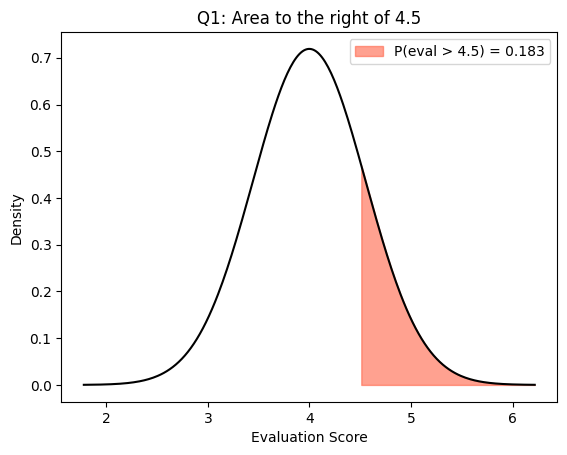


1. Standardising: z = (4.5 - 4.00) / 0.55 = 0.90, so a score of 4.5 is 0.90 standard deviations above the mean.
2. The normal model gives P(eval > 4.5) = 0.1829, so about 18.3% of ratings should exceed 4.5.
3. In the actual data the proportion is 17.1%. The gap between the two figures is the error caused by assuming normality.
4. The shaded area under the curve is the probability: total area = 1, and we are measuring the right tail.



In [7]:
z_45 = (4.5 - mean_score) / std_score
p_greater_4_5 = stats.norm.sf(4.5, loc=mean_score, scale=std_score)   # sf = 1 - cdf
actual_45 = (df['eval'] > 4.5).mean()                                  # real proportion in data

print("z-score of 4.5:", z_45)
print("P(eval > 4.5):", p_greater_4_5)
print("Actual proportion:", actual_45)

# Graph: shade the area we are calculating
xs = np.linspace(mean_score - 4*std_score, mean_score + 4*std_score, 300)
ys = stats.norm.pdf(xs, mean_score, std_score)
plt.plot(xs, ys, color='black')
mask = xs > 4.5
plt.fill_between(xs[mask], ys[mask], color='tomato', alpha=0.6, label=f'P(eval > 4.5) = {p_greater_4_5:.3f}')
plt.xlabel("Evaluation Score")
plt.ylabel("Density")
plt.title("Q1: Area to the right of 4.5")
plt.legend()
plt.show()

print(f"""
1. Standardising: z = (4.5 - {mean_score:.2f}) / {std_score:.2f} = {z_45:.2f}, so a score of 4.5 is {z_45:.2f} standard deviations above the mean.
2. The normal model gives P(eval > 4.5) = {p_greater_4_5:.4f}, so about {p_greater_4_5*100:.1f}% of ratings should exceed 4.5.
3. In the actual data the proportion is {actual_45*100:.1f}%. The gap between the two figures is the error caused by assuming normality.
4. The shaded area under the curve is the probability: total area = 1, and we are measuring the right tail.
""")

 Q2. Using the teachers' rating dataset, what is the probability of receiving an evaluation score greater than 3.5 and less than 4.2

P(3.5 < eval < 4.2): 0.45731592936415527
Actual proportion: 0.3542116630669546


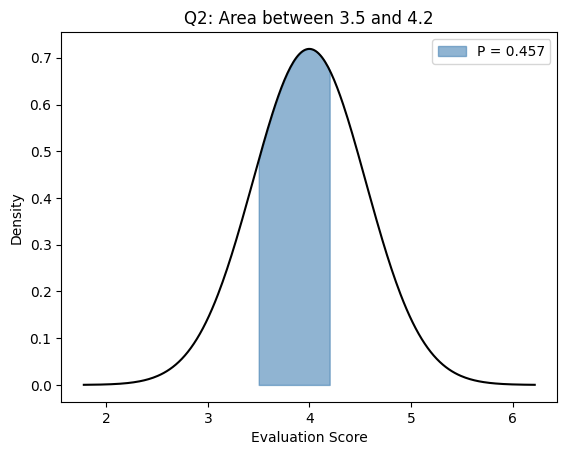


1. The two boundaries convert to z = -0.90 and z = 0.36.
2. Area between two points = cdf(upper) - cdf(lower) = 0.6419 - 0.1846 = 0.4573.
3. So about 45.7% of instructors fall in this range. The actual data shows 35.4%.
4. The range straddles the mean (4.00), so it covers the peak of the curve and gives the largest share of the probability.



In [8]:
z_low = (3.5 - mean_score) / std_score
z_high = (4.2 - mean_score) / std_score
p_lower = stats.norm.cdf(3.5, loc=mean_score, scale=std_score)
p_upper = stats.norm.cdf(4.2, loc=mean_score, scale=std_score)
p_between = p_upper - p_lower
actual_between = ((df['eval'] > 3.5) & (df['eval'] < 4.2)).mean()

print("P(3.5 < eval < 4.2):", p_between)
print("Actual proportion:", actual_between)

# Graph: shade the area between 3.5 and 4.2
xs = np.linspace(mean_score - 4*std_score, mean_score + 4*std_score, 300)
ys = stats.norm.pdf(xs, mean_score, std_score)
plt.plot(xs, ys, color='black')
mask = (xs > 3.5) & (xs < 4.2)
plt.fill_between(xs[mask], ys[mask], color='steelblue', alpha=0.6, label=f'P = {p_between:.3f}')
plt.xlabel("Evaluation Score")
plt.ylabel("Density")
plt.title("Q2: Area between 3.5 and 4.2")
plt.legend()
plt.show()

print(f"""
1. The two boundaries convert to z = {z_low:.2f} and z = {z_high:.2f}.
2. Area between two points = cdf(upper) - cdf(lower) = {p_upper:.4f} - {p_lower:.4f} = {p_between:.4f}.
3. So about {p_between*100:.1f}% of instructors fall in this range. The actual data shows {actual_between*100:.1f}%.
4. The range straddles the mean ({mean_score:.2f}), so it covers the peak of the curve and gives the largest share of the probability.
""")

Q3. Using the two-tailed test from a normal distribution: 1. A professional basketball team wants to compare its performance with that of players in a regional league. 2. The pros are known to have a historic mean of 12 points per game with a standard deviation of 5.5. 3. A group of 36 regional players recorded on average 10.7 points per game. 4. The pro coach would like to know whether his professional team scores on average are different from that of the regional players. State the null hypothesis Null Hypo: ("The mean point of the regional players is not different from the historic mean") Alternative Hypo: ("The mean point of the regional players is different from the historic mean")

Standard error: 0.9166666666666666
Z-score: -1.418181818181819
Critical values: +/- 1.959963984540054
P-value: 0.15613768876786
Fail to Reject Null Hypothesis


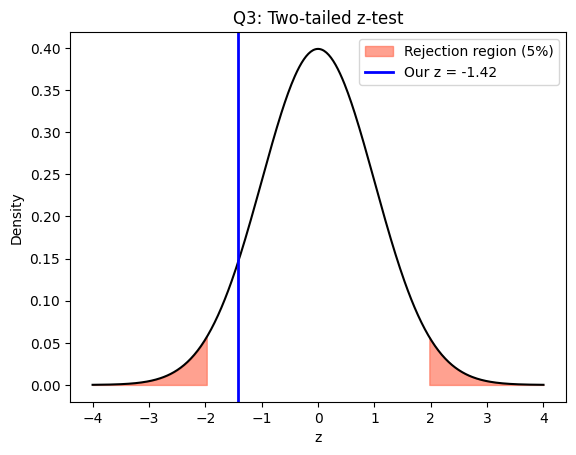


1. The sample mean (10.7) is 1.3 points below the historic mean (12). The standard error is 5.5/sqrt(36) = 0.917.
2. z = -1.418. Our z falls between -1.96 and +1.96, outside the rejection regions.
3. p-value = 0.1561, which is greater than alpha = 0.05. Decision: Fail to Reject Null Hypothesis.
4. In words: the difference of 1.3 points could easily be due to chance, so there is not enough evidence that the means differ.
5. This does NOT prove the means are equal. It only says the data is insufficient. A larger sample might detect a real difference.
6. A z-test is valid here because the population std (5.5) is known and n = 36 is large enough for the sampling distribution to be normal (Central Limit Theorem).



In [9]:
mu, sigma, x_bar, n, alpha = 12, 5.5, 10.7, 36, 0.05

se = sigma / np.sqrt(n)                       # standard error of the mean
z = (x_bar - mu) / se
p_value = 2 * stats.norm.sf(abs(z))           # two-tailed
z_crit = stats.norm.ppf(1 - alpha/2)          # critical value (1.96)

print("Standard error:", se)
print("Z-score:", z)
print("Critical values: +/-", z_crit)
print("P-value:", p_value)

if p_value < alpha:
    decision = "Reject Null Hypothesis"
else:
    decision = "Fail to Reject Null Hypothesis"
print(decision)

# Graph: rejection regions vs our z-score
xs = np.linspace(-4, 4, 400)
ys = stats.norm.pdf(xs)
plt.plot(xs, ys, color='black')
plt.fill_between(xs[xs <= -z_crit], ys[xs <= -z_crit], color='tomato', alpha=0.6, label='Rejection region (5%)')
plt.fill_between(xs[xs >= z_crit], ys[xs >= z_crit], color='tomato', alpha=0.6)
plt.axvline(z, color='blue', linewidth=2, label=f'Our z = {z:.2f}')
plt.xlabel("z")
plt.ylabel("Density")
plt.title("Q3: Two-tailed z-test")
plt.legend()
plt.show()

print(f"""
1. The sample mean ({x_bar}) is {abs(x_bar - mu):.1f} points below the historic mean ({mu}). The standard error is {sigma}/sqrt({n}) = {se:.3f}.
2. z = {z:.3f}. Our z falls between -{z_crit:.2f} and +{z_crit:.2f}, outside the rejection regions.
3. p-value = {p_value:.4f}, which is greater than alpha = {alpha}. Decision: {decision}.
4. In words: the difference of {abs(x_bar - mu):.1f} points could easily be due to chance, so there is not enough evidence that the means differ.
5. This does NOT prove the means are equal. It only says the data is insufficient. A larger sample might detect a real difference.
6. A z-test is valid here because the population std ({sigma}) is known and n = {n} is large enough for the sampling distribution to be normal (Central Limit Theorem).
""")